## Urban Landcover Data

Landcover Data

In [1]:
import zarr

store = zarr.open("/net/data/arceme/lcover_data/ESACCI_2016_2023.zarr", mode="r")
print(store.tree())


/
 ├── band (8,) int64
 ├── band_data (8, 64800, 129600) float32
 ├── x (129600,) float64
 └── y (64800,) float64


In [2]:
import xarray as xr

ds = xr.open_zarr("/net/data/arceme/lcover_data/ESACCI_2016_2023.zarr")
print(ds)
print(ds.data_vars)
print(ds.coords)
print(ds.attrs)


<xarray.Dataset>
Dimensions:    (band: 8, y: 64800, x: 129600)
Coordinates:
  * band       (band) int64 2016 2017 2018 2019 2020 2021 2022 2023
  * x          (x) float64 -180.0 -180.0 -180.0 -180.0 ... 180.0 180.0 180.0
  * y          (y) float64 90.0 90.0 89.99 89.99 ... -89.99 -89.99 -90.0 -90.0
Data variables:
    band_data  (band, y, x) float32 dask.array<chunksize=(1, 6000, 4000), meta=np.ndarray>
Data variables:
    band_data  (band, y, x) float32 dask.array<chunksize=(1, 6000, 4000), meta=np.ndarray>
Coordinates:
  * band     (band) int64 2016 2017 2018 2019 2020 2021 2022 2023
  * x        (x) float64 -180.0 -180.0 -180.0 -180.0 ... 180.0 180.0 180.0 180.0
  * y        (y) float64 90.0 90.0 89.99 89.99 ... -89.99 -89.99 -90.0 -90.0
{}


In [3]:
import xarray as xr

lc = xr.open_zarr("/net/data/arceme/lcover_data/ESACCI_2016_2023.zarr")
lc = lc.rename({'band_data': 'lccs'})   # friendlier name


In [4]:
lc2020 = lc.lccs.sel(band=2020)
print(lc2020)

<xarray.DataArray 'lccs' (y: 64800, x: 129600)>
dask.array<getitem, shape=(64800, 129600), dtype=float32, chunksize=(6000, 4000), chunktype=numpy.ndarray>
Coordinates:
    band     int64 2020
  * x        (x) float64 -180.0 -180.0 -180.0 -180.0 ... 180.0 180.0 180.0 180.0
  * y        (y) float64 90.0 90.0 89.99 89.99 ... -89.99 -89.99 -90.0 -90.0


In [5]:
import rioxarray
lc2020 = lc2020.rio.write_crs("EPSG:4326")


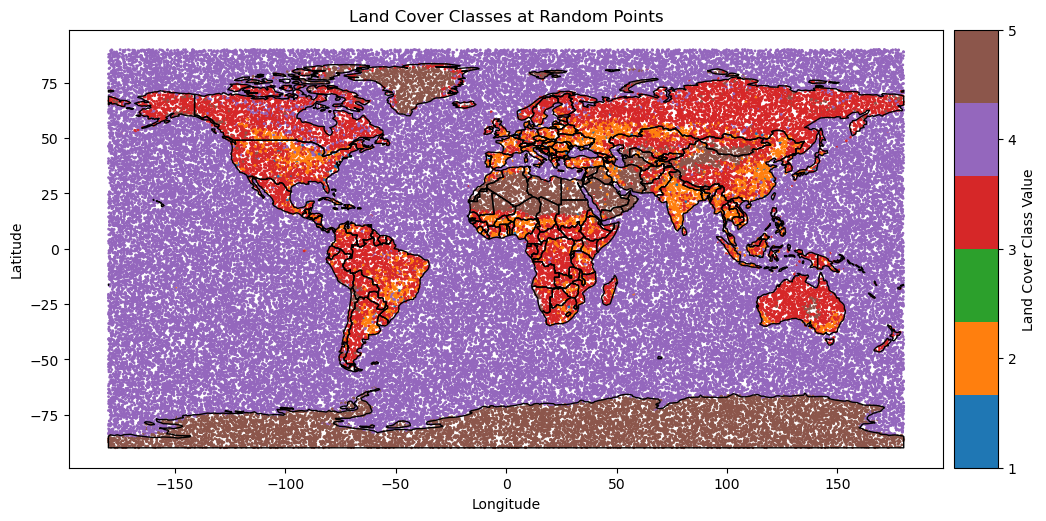

In [ ]:
import matplotlib.pyplot as plt
import geopandas as gpd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.colors import ListedColormap

# Define a discrete colormap
categories = np.unique(df['Value'])
cmap = ListedColormap(plt.cm.tab10.colors[:len(categories)])

world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
fig, ax = plt.subplots(figsize=(12, 6))
world.boundary.plot(ax=ax, linewidth=1, edgecolor='black')

# Plot the data
sc = ax.scatter(df['Longitude'], df['Latitude'], c=df['Value'], cmap=cmap, s=1, alpha=1)
ax.set_title('Land Cover Classes at Random Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Create colorbar
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.1)
cbar = plt.colorbar(sc, cax=cax, ticks=categories)
cbar.set_label('Land Cover Class Value')
cbar.ax.set_yticklabels(categories.astype(int))  # Ensure labels are integers

plt.show()

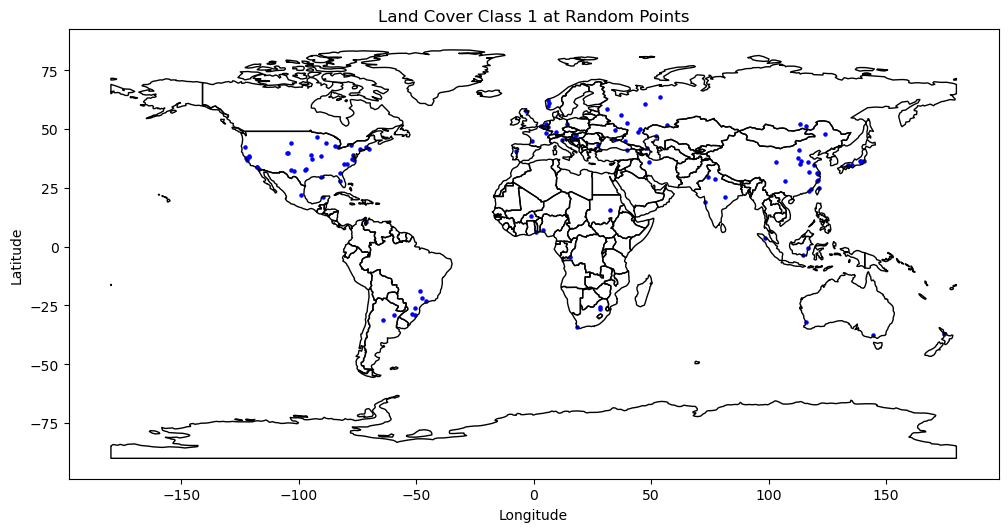

In [ ]:
# Filter the DataFrame for Value == 1
df_filtered = df[df['Value'] == 1]

# Plot the filtered data
fig, ax = plt.subplots(figsize=(12, 6))
world.boundary.plot(ax=ax, linewidth=1, edgecolor='black')

sc = ax.scatter(df_filtered['Longitude'], df_filtered['Latitude'], c='blue', s=5, alpha=1)
ax.set_title('Land Cover Class 1 at Random Points')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

plt.show()


In [ ]:
import numpy as np
import pandas as pd

# Example: somewhere in central London

# Generate random sample for 1000 points
np.random.seed(42)  # for reproducibility
example_lon = np.random.uniform(-180, 180, 100000)
example_lat = np.random.uniform(-90, 90, 100000)

# Select nearest pixel for all random points
vals = lc2020.sel(
    x=xr.DataArray(example_lon, dims="points"),
    y=xr.DataArray(example_lat, dims="points"),
    method='nearest'
).compute().values
# Create a DataFrame with the values and corresponding coordinates
df =c pd.DataFrame({
    'Longitude': example_lon,
    'Latitude': example_lat,
    'Value': vals
})

print(df.head())

# Print summary statistics
print("Summary statistics of selected values:")
print(f"Min: {vals.min()}")
print(f"Max: {vals.max()}")
print(f"Mean: {vals.mean()}")
print(f"Std Dev: {vals.std()}")
print(f"Unique values: {np.unique(vals)}")


    Longitude   Latitude  Value
0  -45.165557  14.540228    4.0
1  162.257150   4.854897    4.0
2   83.517819 -26.813349    4.0
3   35.517054  -1.221722    2.0
4 -123.833289 -24.282606    4.0
Summary statistics of selected values:
Min: nan
Max: nan
Mean: nan
Std Dev: nan
Unique values: [ 1.  2.  3.  4.  5. nan]


In [8]:
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.geometry import Point

# -------------------------------
# 1. Config
# -------------------------------
csv_file = "/net/scratch/swolf/GBIF/GBIF_try6_GloNAF_WCVP_status_woodiness_CS.csv"
zarr_file = "/net/data/arceme/lcover_data/ESACCI_2016_2023.zarr"
year = 2023
chunk_size = 1_000_000

# -------------------------------
# 2. Open Zarr
# -------------------------------
lc = xr.open_zarr(zarr_file)
lc = lc.rename({'band_data': 'lccs'})
lc_year = lc.lccs.sel(band=year)

# -------------------------------
# 3. Read CSV in chunks and extract values
# -------------------------------
urban_flags = []

for chunk in pd.read_csv(csv_file,
                         usecols=["gbifID", "decimalLatitude", "decimalLongitude"],
                         chunksize=chunk_size):

    # Convert to GeoDataFrame
    gdf = gpd.GeoDataFrame(
        chunk,
        geometry=[Point(xy) for xy in zip(chunk.decimalLongitude, chunk.decimalLatitude)],
        crs="EPSG:4326"
    )

    # Raster lookup
    lc_vals = lc_year.sel(
        x=xr.DataArray(gdf.geometry.x, dims="points"),
        y=xr.DataArray(gdf.geometry.y, dims="points"),
        method="nearest"
    ).compute().values

    # Save raw values directly
    gdf['landcover_value'] = lc_vals

    # Append only columns we want
    urban_flags.append(gdf[['gbifID', 'landcover_value']])

# -------------------------------
# 4. Combine everything
# -------------------------------
result = pd.concat(urban_flags, ignore_index=True)
print(result.head())

# Save
result.to_csv("/net/scratch/swolf/GBIF_landcover_values_2023.csv", index=False)


      gbifID  landcover_value
0  891018389              3.0
1  891018395              2.0
2  891018399              3.0
3  891018400              3.0
4  891018401              3.0


In [5]:
import xarray as xr
import numpy as np
import pandas as pd
import h3

In [6]:
lc_year = lc.lccs.sel(band=2023)

In [7]:
lc_masked = lc_year.where(~lc_year.isin([4]))

In [18]:
urban = (lc_year == 1).coarsen(x=20, y=20).mean()
crop  = (lc_year == 2).coarsen(x=20, y=20).mean()
nat   = (lc_year == 3).coarsen(x=20, y=20).mean()
water = (lc_year == 4).coarsen(x=20, y=20).mean()
barren = (lc_year == 5).coarsen(x=20, y=20).mean()

In [19]:
urban

<xarray.DataArray 'lccs' (y: 3240, x: 6480)>
dask.array<mean_agg-aggregate, shape=(3240, 6480), dtype=float64, chunksize=(300, 200), chunktype=numpy.ndarray>
Coordinates:
    band     int64 2023
  * x        (x) float64 -180.0 -179.9 -179.9 -179.8 ... 179.8 179.9 179.9 180.0
  * y        (y) float64 89.97 89.92 89.86 89.81 ... -89.81 -89.86 -89.92 -89.97

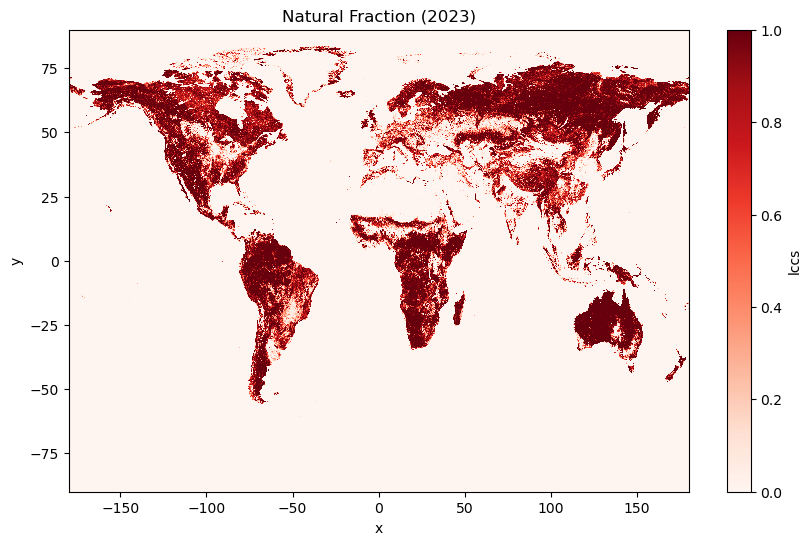

In [20]:
import matplotlib.pyplot as plt

nat.plot(cmap="Reds", vmin=0, vmax=1, figsize=(10,6))
plt.title("Natural Fraction (2023)")
plt.show()

In [21]:
# convert urban, corp and nat to dataframe
df_urban = urban.to_dataframe().reset_index()
df_crop = crop.to_dataframe().reset_index()
df_nat = nat.to_dataframe().reset_index()
df_water = water.to_dataframe().reset_index()
df_barren = barren.to_dataframe().reset_index()


In [28]:
df_nat.head()

,y,x,band,lccs
0,89.972222,-179.972222,2023,0.0
1,89.972222,-179.916667,2023,0.0
2,89.972222,-179.861111,2023,0.0
3,89.972222,-179.805556,2023,0.0
4,89.972222,-179.750000,2023,0.0


In [45]:
# Merge all three dataframes on x and y coordinates
df_merged = df_urban.merge(df_crop, on=['x', 'y', 'band'], suffixes=('_urban', '_crop'))
df_merged = df_merged.merge(df_nat, on=['x', 'y', 'band'])
df_merged = df_merged.rename(columns={'lccs': 'lccs_nat'})
df_merged = df_merged.merge(df_barren, on=['x', 'y', 'band'])
df_merged = df_merged.rename(columns={'lccs': 'lccs_barren'})
df_merged = df_merged.merge(df_water, on=['x', 'y', 'band'])
df_merged = df_merged.rename(columns={'lccs': 'lccs_water'})

print(df_merged.head())


           y           x  band  lccs_urban  lccs_crop  lccs_nat  lccs_barren  \
0  89.972222 -179.972222  2023         0.0        0.0       0.0          0.0   
1  89.972222 -179.916667  2023         0.0        0.0       0.0          0.0   
2  89.972222 -179.861111  2023         0.0        0.0       0.0          0.0   
3  89.972222 -179.805556  2023         0.0        0.0       0.0          0.0   
4  89.972222 -179.750000  2023         0.0        0.0       0.0          0.0   

   lccs_water  
0         1.0  
1         1.0  
2         1.0  
3         1.0  
4         1.0  


In [46]:
# dimenstions of the merged dataframe
print(df_merged.shape)

(20995200, 8)


In [48]:
df_merged.head()

,y,x,band,lccs_urban,lccs_crop,lccs_nat,lccs_barren,lccs_water
0,89.972222,-179.972222,2023,0.0,0.0,0.0,0.0,1.0
1,89.972222,-179.916667,2023,0.0,0.0,0.0,0.0,1.0
2,89.972222,-179.861111,2023,0.0,0.0,0.0,0.0,1.0
3,89.972222,-179.805556,2023,0.0,0.0,0.0,0.0,1.0
4,89.972222,-179.750000,2023,0.0,0.0,0.0,0.0,1.0


In [ ]:
# filter out rows where all three land cover fractions are zero
#df_merged = df_merged[~((df_merged['lccs_urban'] == 0.0) & (df_merged['lccs_crop'] == 0.0)  & (df_merged['lccs_nat'] == 0.0)) & (df_merged['lccs_barren'] == 0.0) & (df_merged['lccs_water'] == 0.0) ]

In [ ]:
# dimenstions of the merged dataframe
#print(df_merged.shape)

(2677173, 8)


In [40]:
df_merged.head()

,y,x,band,lccs_urban,lccs_crop,lccs_nat,lccs_barren,lccs_water
754325,83.527778,-33.027778,2023,0.0,0.0,1.0,0.0,0.0
754326,83.527778,-32.972222,2023,0.0,0.0,1.0,0.0,0.0
754327,83.527778,-32.916667,2023,0.0,0.0,1.0,0.0,0.0
754332,83.527778,-32.638889,2023,0.0,0.0,1.0,0.0,0.0
754333,83.527778,-32.583333,2023,0.0,0.0,1.0,0.0,0.0


In [49]:
# recalculate the fractions to ensure they sum to 1
df_merged['total'] = df_merged['lccs_urban'] + df_merged['lccs_crop'] + df_merged['lccs_nat'] + df_merged['lccs_barren'] + df_merged['lccs_water']
df_merged['lccs_urban'] = df_merged['lccs_urban'] / df_merged['total']
df_merged['lccs_crop'] = df_merged['lccs_crop'] / df_merged['total']
df_merged['lccs_nat'] = df_merged['lccs_nat'] / df_merged['total']  
df_merged['lccs_barren'] = df_merged['lccs_barren'] / df_merged['total']
df_merged['lccs_water'] = df_merged['lccs_water'] / df_merged['total']

In [51]:
df_merged.tail()

,y,x,band,lccs_urban,lccs_crop,lccs_nat,lccs_barren,lccs_water,total
20995195,-89.972222,179.750000,2023,0.0,0.0,0.0,1.0,0.0,0.9500
20995196,-89.972222,179.805556,2023,0.0,0.0,0.0,1.0,0.0,0.9500
20995197,-89.972222,179.861111,2023,0.0,0.0,0.0,1.0,0.0,0.9500
20995198,-89.972222,179.916667,2023,0.0,0.0,0.0,1.0,0.0,0.9500
20995199,-89.972222,179.972222,2023,0.0,0.0,0.0,1.0,0.0,0.9025


In [52]:
# save to csv
df_merged.to_csv("/net/scratch/swolf/landcover_fractions_2023_all.csv", index=False)

<Figure size 1000x600 with 0 Axes>

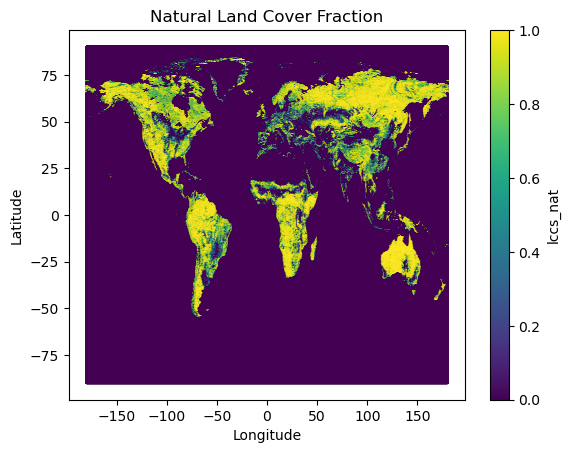

In [53]:
import matplotlib.pyplot as plt

# plot df_merged
plt.figure(figsize=(10, 6))
df_merged.plot(x='x', y='y', kind='scatter', c='lccs_nat', cmap='viridis', s=0.5, alpha=1)
plt.title('Natural Land Cover Fraction')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


<Figure size 1000x600 with 0 Axes>

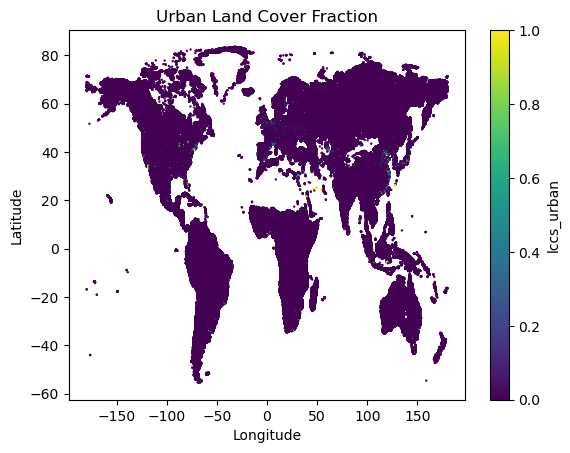

In [34]:
import matplotlib.pyplot as plt

# plot df_urban
plt.figure(figsize=(10, 6))
df_merged.plot(x='x', y='y', kind='scatter', c='lccs_urban', cmap='viridis', s=0.5, alpha=1)
plt.title('Urban Land Cover Fraction')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()


<Figure size 1000x600 with 0 Axes>

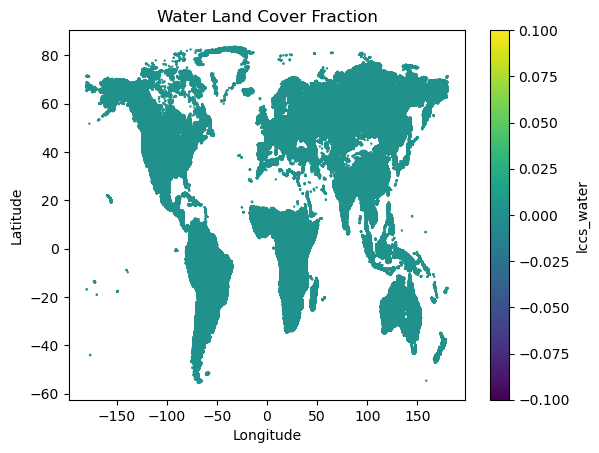

In [44]:
import matplotlib.pyplot as plt

# plot df_merged
plt.figure(figsize=(10, 6))
df_merged.plot(x='x', y='y', kind='scatter', c='lccs_water', cmap='viridis', s=0.5, alpha=1)
plt.title('Water Land Cover Fraction')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# plot df_merged
plt.figure(figsize=(10, 6))
df_merged.plot(x='x', y='y', kind='scatter', c='lccs_water', cmap='viridis', s=0.5, alpha=1)
plt.title('Water Land Cover Fraction')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

<Figure size 1000x600 with 0 Axes>

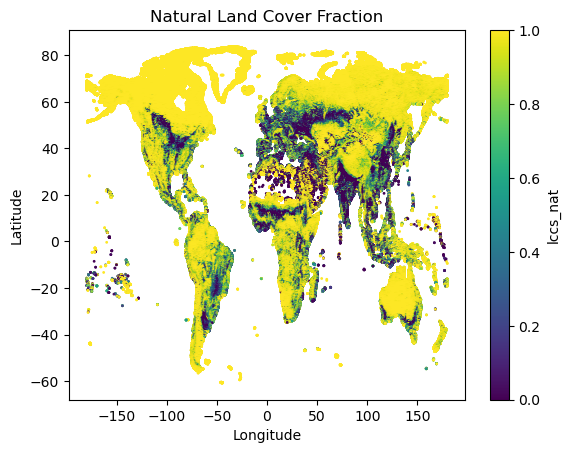

In [24]:
import matplotlib.pyplot as plt

# plot df_urban
plt.figure(figsize=(10, 6))
df_merged.plot(x='x', y='y', kind='scatter', c='lccs_nat', cmap='viridis', s=1, alpha=1)
plt.title('Natural Land Cover Fraction')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

In [36]:
import h3

df["h3"] = [
    h3.latlng_to_cell(lat, lon, 3)
    for lat, lon in zip(df["y"].to_numpy(), df["x"].to_numpy())
]

AttributeError: module 'h3' has no attribute 'latlng_to_cell'